In [16]:
import pandas as pd

gpt = pd.read_csv("/home/dbtproject/barsha/LLM/GPT_Result.csv")
gemini = pd.read_csv("/home/dbtproject/barsha/LLM/Gemini_Result.csv")

gpt = gpt.rename(
    columns={"Predicted_Class":"GPT_Pred"}
)

gemini = gemini.rename(
    columns={"Predicted_Class":"Gemini_Pred"}
)

In [17]:
merged = pd.merge(
    gpt,
    gemini[["Filename","Gemini_Pred"]],
    on="Filename"
)

print(merged.head(20))

        Filename Original_Class       GPT_Pred    Gemini_Pred
0     test_img_1  M_Graminicola  M_Graminicola  M_Graminicola
1     test_img_2  M_Graminicola     M_Javanica    M_Incognita
2     test_img_3  M_Graminicola  M_Graminicola     M_Javanica
3     test_img_4  M_Graminicola  M_Graminicola  M_Graminicola
4     test_img_5  M_Graminicola  M_Graminicola     M_Javanica
5     test_img_6  M_Graminicola  M_Graminicola  M_Graminicola
6     test_img_7  M_Graminicola  M_Graminicola     M_Javanica
7     test_img_8  M_Graminicola  M_Graminicola  M_Graminicola
8     test_img_9  M_Graminicola  M_Graminicola    M_Incognita
9    test_img_10  M_Graminicola  M_Graminicola  M_Graminicola
10   test_img_31  M_Graminicola  M_Graminicola    M_Incognita
11   test_img_32  M_Graminicola  M_Graminicola     M_Javanica
12   test_img_33  M_Graminicola  M_Graminicola  M_Graminicola
13   test_img_34  M_Graminicola  M_Graminicola    M_Incognita
14   test_img_35  M_Graminicola  M_Graminicola  M_Graminicola
15   tes

In [18]:
merged["GPT_Correct"] = (
    merged["Original_Class"]
    ==
    merged["GPT_Pred"]
)

merged["Gemini_Correct"] = (
    merged["Original_Class"]
    ==
    merged["Gemini_Pred"]
)

In [20]:
print(merged.head(20))

        Filename Original_Class       GPT_Pred    Gemini_Pred  GPT_Correct  \
0     test_img_1  M_Graminicola  M_Graminicola  M_Graminicola         True   
1     test_img_2  M_Graminicola     M_Javanica    M_Incognita        False   
2     test_img_3  M_Graminicola  M_Graminicola     M_Javanica         True   
3     test_img_4  M_Graminicola  M_Graminicola  M_Graminicola         True   
4     test_img_5  M_Graminicola  M_Graminicola     M_Javanica         True   
5     test_img_6  M_Graminicola  M_Graminicola  M_Graminicola         True   
6     test_img_7  M_Graminicola  M_Graminicola     M_Javanica         True   
7     test_img_8  M_Graminicola  M_Graminicola  M_Graminicola         True   
8     test_img_9  M_Graminicola  M_Graminicola    M_Incognita         True   
9    test_img_10  M_Graminicola  M_Graminicola  M_Graminicola         True   
10   test_img_31  M_Graminicola  M_Graminicola    M_Incognita         True   
11   test_img_32  M_Graminicola  M_Graminicola     M_Javanica   

In [ ]:
def agreement_category(row):

    if row["GPT_Correct"] and row["Gemini_Correct"]:
        return "Both Correct"

    elif row["GPT_Correct"] and not row["Gemini_Correct"]:
        return "GPT Only Correct"

    elif not row["GPT_Correct"] and row["Gemini_Correct"]:
        return "Gemini Only Correct"

    else:
        return "Both Wrong"

merged["Agreement"] = merged.apply(
    agreement_category,
    axis=1
)


In [7]:
agreement_counts = (
    merged["Agreement"]
    .value_counts()
)

print(agreement_counts)

Agreement
Both Correct           40
GPT Only Correct       17
Both Wrong              2
Gemini Only Correct     1
Name: count, dtype: int64


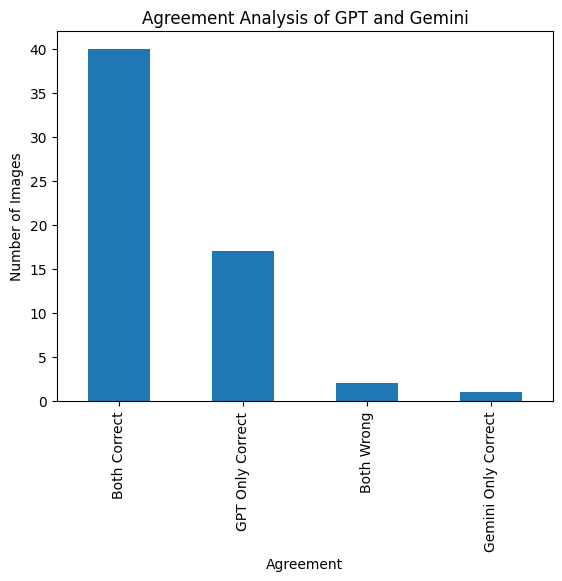

In [8]:
import matplotlib.pyplot as plt

agreement_counts.plot(
    kind="bar"
)

plt.ylabel("Number of Images")
plt.title(
    "Agreement Analysis of GPT and Gemini"
)

plt.show()

In [9]:
gpt_unique = merged[
    (merged["GPT_Correct"] == True)
    &
    (merged["Gemini_Correct"] == False)
]

print(gpt_unique)

        Filename Original_Class       GPT_Pred    Gemini_Pred  GPT_Correct  \
2     test_img_3  M_Graminicola  M_Graminicola     M_Javanica         True   
4     test_img_5  M_Graminicola  M_Graminicola     M_Javanica         True   
6     test_img_7  M_Graminicola  M_Graminicola     M_Javanica         True   
8     test_img_9  M_Graminicola  M_Graminicola    M_Incognita         True   
10   test_img_31  M_Graminicola  M_Graminicola    M_Incognita         True   
11   test_img_32  M_Graminicola  M_Graminicola     M_Javanica         True   
13   test_img_34  M_Graminicola  M_Graminicola    M_Incognita         True   
15   test_img_36  M_Graminicola  M_Graminicola    M_Incognita         True   
16   test_img_37  M_Graminicola  M_Graminicola     M_Javanica         True   
19   test_img_40  M_Graminicola  M_Graminicola     M_Javanica         True   
26   test_img_17    M_Incognita    M_Incognita     M_Javanica         True   
31   test_img_42    M_Incognita    M_Incognita     M_Javanica   

In [10]:
gemini_unique = merged[
    (merged["GPT_Correct"] == False)
    &
    (merged["Gemini_Correct"] == True)
]

print(gemini_unique)

       Filename Original_Class    GPT_Pred  Gemini_Pred  GPT_Correct  \
39  test_img_50    M_Incognita  M_Javanica  M_Incognita        False   

    Gemini_Correct            Agreement  
39            True  Gemini Only Correct  


In [11]:
both_wrong = merged[
    (merged["GPT_Correct"] == False)
    &
    (merged["Gemini_Correct"] == False)
]

print(both_wrong)

        Filename Original_Class     GPT_Pred  Gemini_Pred  GPT_Correct  \
1     test_img_2  M_Graminicola   M_Javanica  M_Incognita        False   
18   test_img_39  M_Graminicola  M_Incognita  M_Incognita        False   

    Gemini_Correct   Agreement  
1            False  Both Wrong  
18           False  Both Wrong  


In [12]:
pd.crosstab(
    merged["Original_Class"],
    merged["Agreement"]
)

Agreement,Both Correct,Both Wrong,GPT Only Correct,Gemini Only Correct
Original_Class,,,,
M_Graminicola,8,2,10,0
M_Incognita,14,0,5,1
M_Javanica,18,0,2,0
